<a href="https://colab.research.google.com/github/IzzaDhafira/Pembelajaran_Mesin_2026/blob/main/T4_244107020106_IzzaDhafiraFanani.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv('Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
# Seleksi Fitur

X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

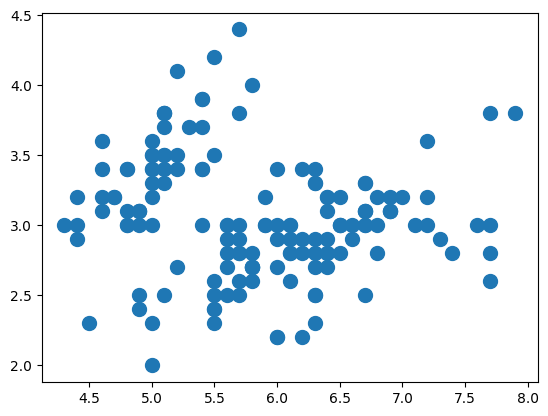

In [6]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width  saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

In [7]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

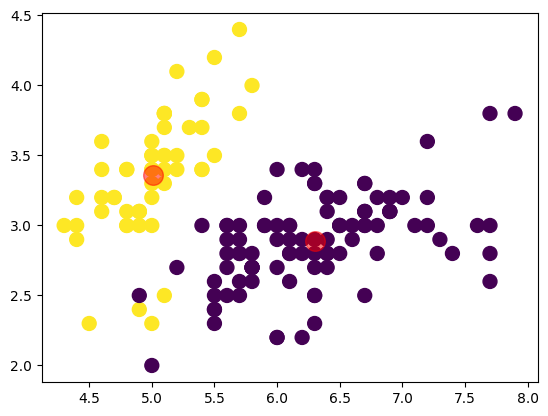

In [8]:
# Plot hasi cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

In [9]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


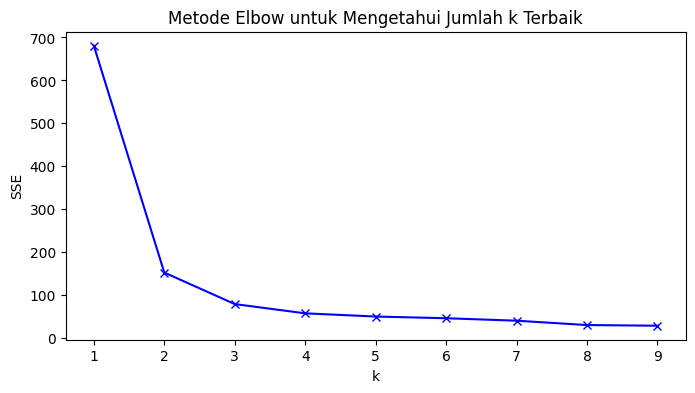

In [11]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [12]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94084142614601
k=4; SSE=57.34540931571815
k=5; SSE=49.91714055829228
k=6; SSE=45.943239459391194
k=7; SSE=40.198026272578005
k=8; SSE=30.077530998389694
k=9; SSE=28.505858841450948


# **PRAKTIKUM 2**

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

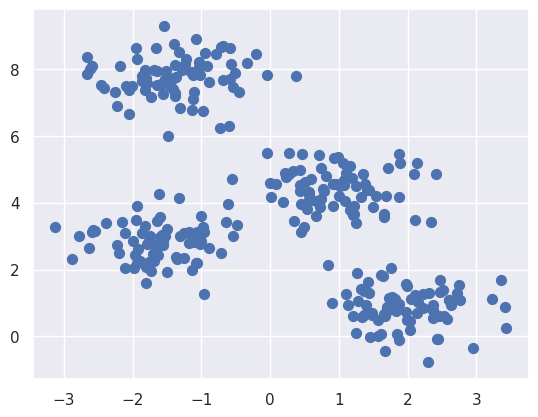

In [17]:
# Pengantar k-Means
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50);

In [15]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

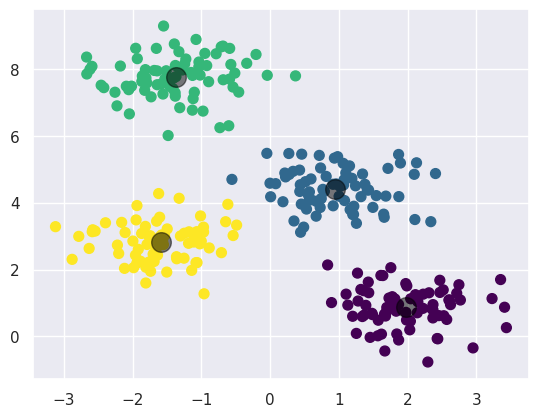

In [16]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

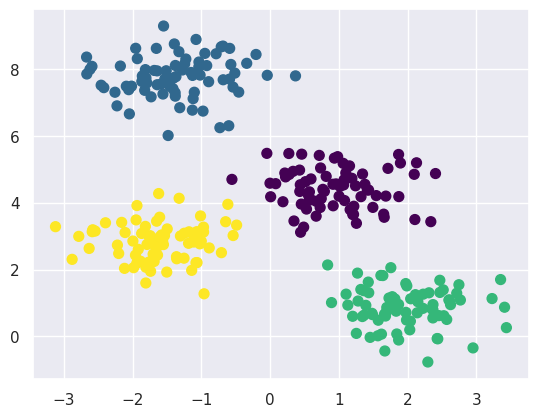

In [18]:
# Algoritma Expectation-Maximization

from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)

        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])

        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

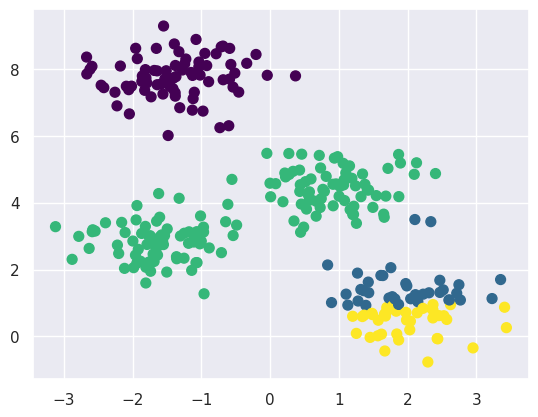

In [19]:
# Perubahan random

centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

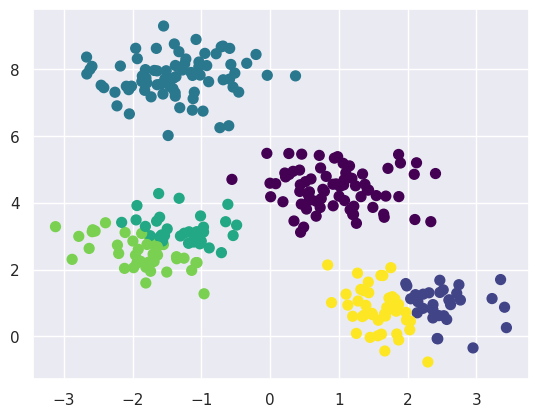

In [20]:
# Optimalisasi Jumlah Klaster

labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

In [22]:
# Batas Klaster yang Tidak Selalu Linier

from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

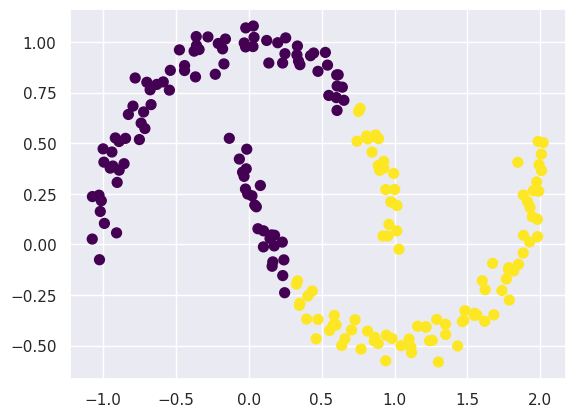

In [23]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


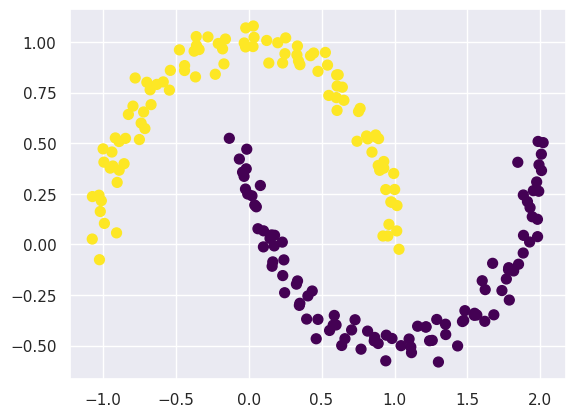

In [24]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

In [25]:
# Contoh Kasus 1: Karakter Angka

from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

In [26]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

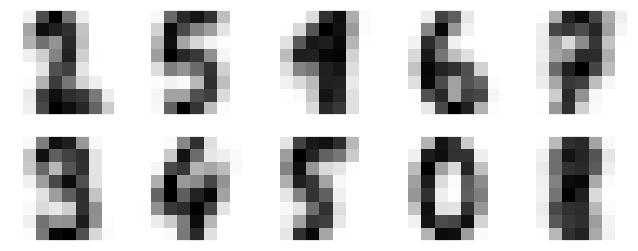

In [27]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

In [28]:
from scipy.stats import mode

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

In [29]:
from sklearn.metrics import accuracy_score
accuracy_score(digits.target, labels)

0.7440178074568725

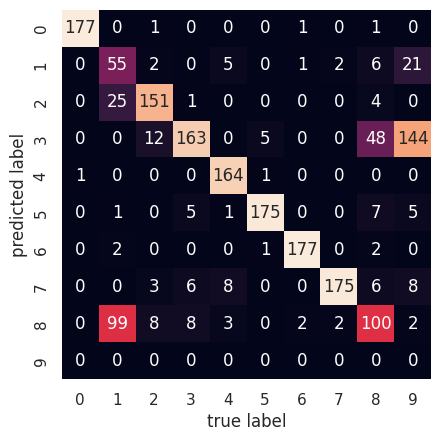

In [30]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

In [31]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

# hitung klaster
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9410127991096272

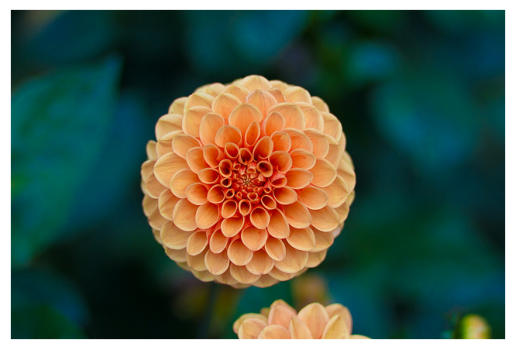

In [32]:
# Studi Kasus 2: Kompresi Citra

from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

In [33]:
flower.shape

(427, 640, 3)

In [34]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

In [35]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

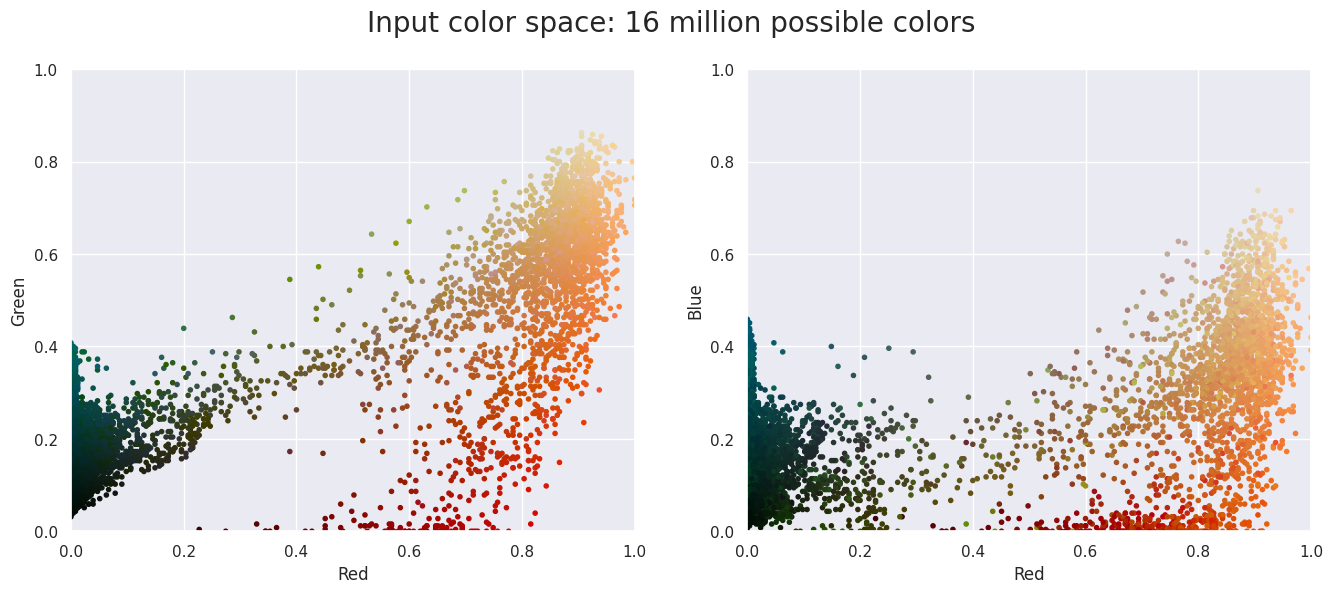

In [36]:
plot_pixels(data, title='Input color space: 16 million possible colors')

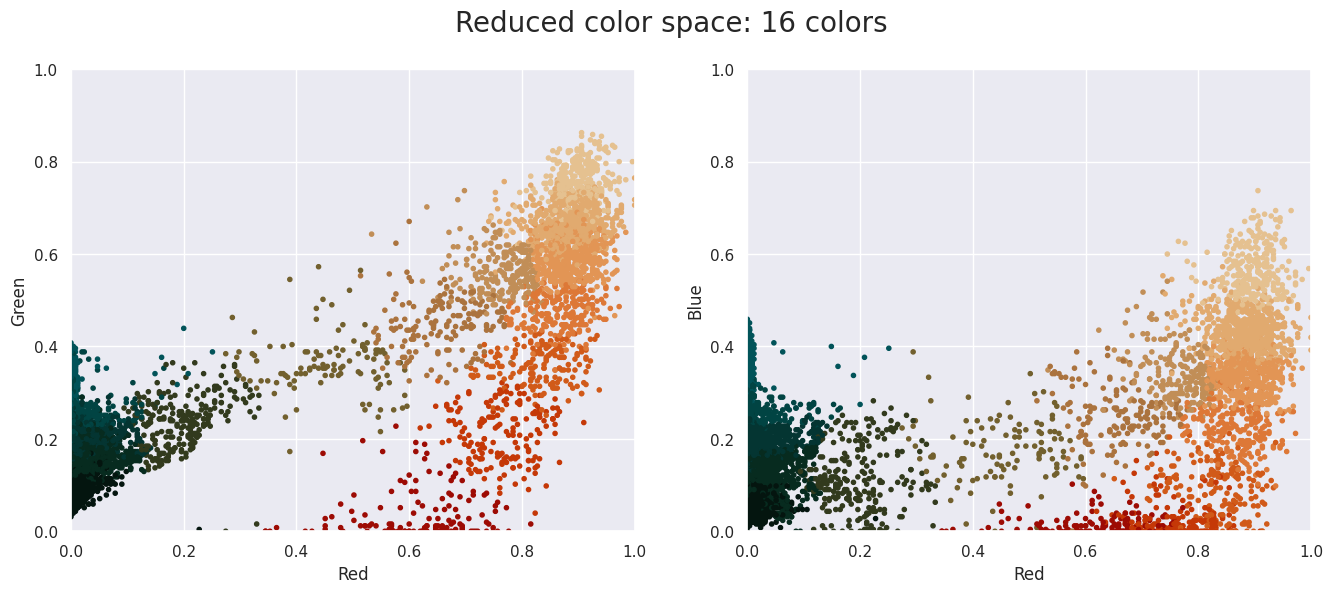

In [37]:
import warnings; warnings.simplefilter('ignore')  # Fix NumPy issues.

from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

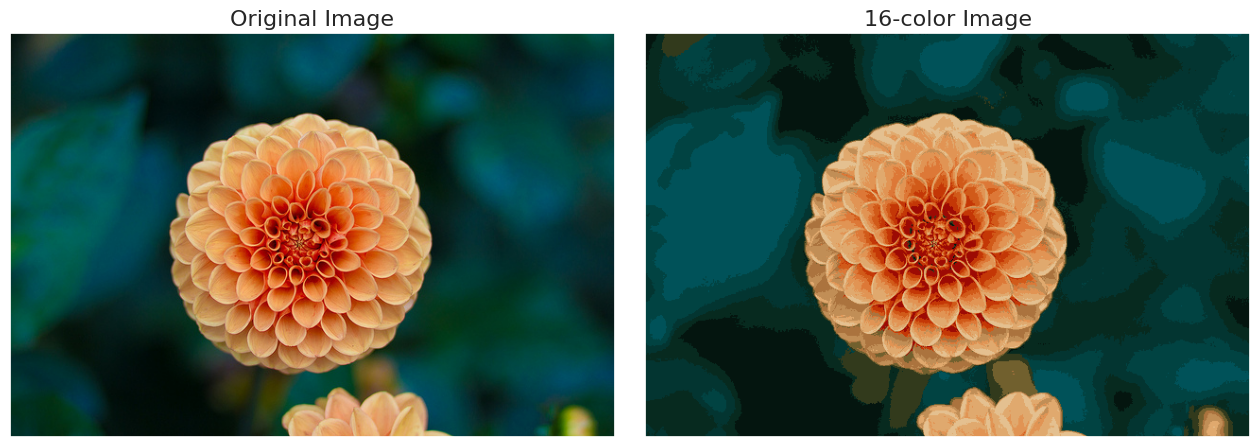

In [38]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

# **PRAKTIKUM 3**

In [41]:
# Pembuatan Dataset Sintetis

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

X = StandardScaler().fit_transform(X)

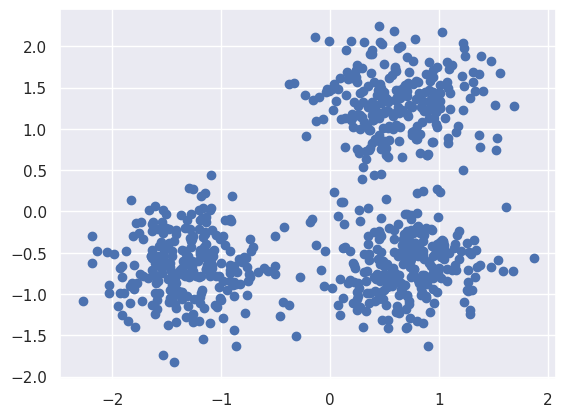

In [43]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])
plt.show()

In [46]:
# Compute DBSCAN

import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


In [49]:
# Evaluasi Kualitas Klasterisasi

from sklearn import metrics

print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626



Homogeneity → apakah tiap klaster hanya berisi satu label asli.

Completeness → apakah semua sampel dengan label asli yang sama masuk ke klaster yang sama.

V-measure → rata-rata harmonik dari homogeneity dan completeness.

Adjusted Rand Index (ARI) → kesesuaian antara klasterisasi dengan label asli.

Adjusted Mutual Information (AMI) → kesamaan informasi antara klasterisasi dengan label asli.

Silhouette Coefficient → seberapa baik data dikelompokkan (nilai mendekati 1 berarti bagus, mendekati 0 berarti berada di batas, negatif berarti salah klaster).

()

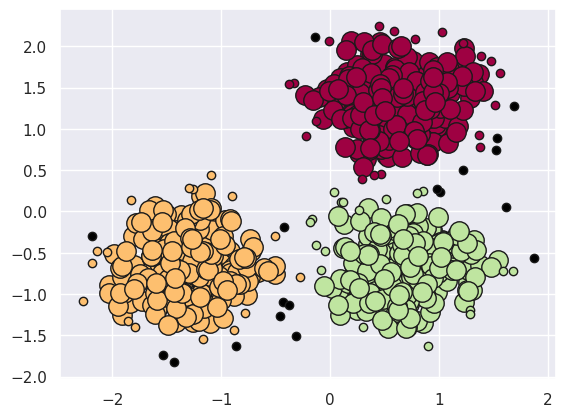

In [53]:
# Visualisasi Hasil Klasterisasi

# Core sample ditampilkan dengan titik besar.
# Non-core sample ditampilkan dengan titik kecil.
# Noise ditampilkan dengan warna hitam.

unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

(f"Estimated number of clusters: {n_clusters_}")
()

**Interpretasi visual:**

Titik besar berwarna → core samples dalam klaster.

Titik kecil berwarna → non-core samples, tetap termasuk klaster.

Titik hitam → noise/outlier.

# **TUGAS PRAKTIKUM**

**Tugas K-Means**

Buatlah sebuah model K-Means dengan ketentuan,

1. Gunakan data 'Mall_Customers.csv'

2. Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2)

3. Buatlah model K-Means dengan mempertimbangkan jumlah k yang terbaik.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [56]:
# 1. Membaca dataset
df = pd.read_csv('Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [57]:
# 2. Menentukan fitur untuk clustering (Annual Income & Spending Score)
X_kmeans = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

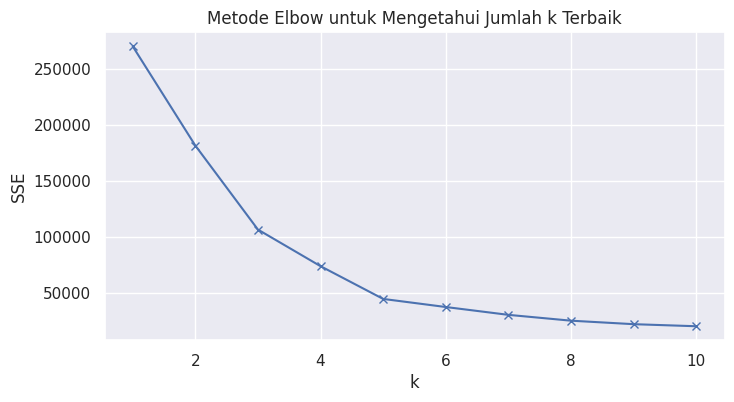

In [67]:
# 3. Mencari nilai k terbaik dengan Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-11
K = range(1, 11)

# Cek nilai SSE setiap k
for k in K:
    kmeansModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeansModel.fit(X_kmeans)
    sse.append(kmeansModel.inertia_)

# Menampilkan grafik Elbow
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.title('Metode Elbow untuk Mengetahui Jumlah k Terbaik')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

In [68]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=269981.28000000014
k=2; SSE=181363.59595959607
k=3; SSE=106348.37306211119
k=4; SSE=73679.78903948837
k=5; SSE=44448.45544793369
k=6; SSE=37233.81451071002
k=7; SSE=30241.34361793659
k=8; SSE=25036.417604033977
k=9; SSE=21916.79478984372
k=10; SSE=20072.070939404


In [69]:
# 4. Membuat model K-Means dengan k=5 (berdasarkan siku/elbow terkuat pada grafik)
kmeans_opt = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_opt = kmeans_opt.fit_predict(X_kmeans)

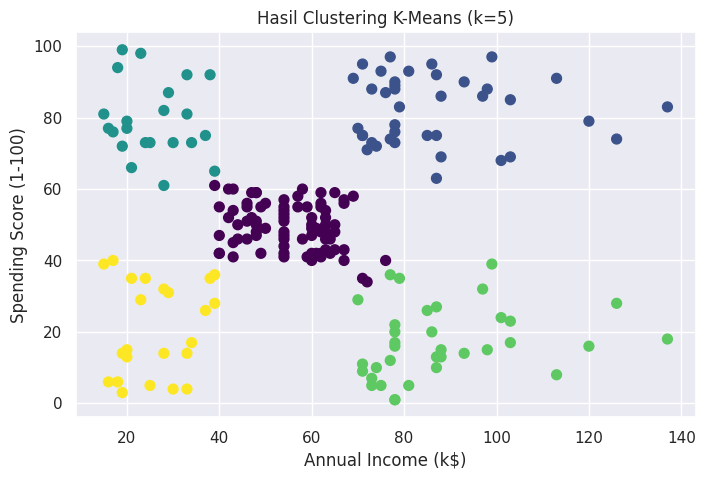

In [70]:
# Visualisasi hasil K-Means
plt.figure(figsize=(8, 5))
plt.scatter(X_kmeans[:, 0], X_kmeans[:, 1], c=labels_opt, cmap='viridis', s=50)
plt.title('Hasil Clustering K-Means (k=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

**Tugas DBSCAN**

1. Buat dataset make_moons (1000 sampel, noise=0.05), lalu normalisasi.
2. Jalankan DBSCAN dengan eps=0.2, min_samples=5, hitung jumlah klaster & noise.
3. Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.
4. Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam).
5. Lakukan eksperimen:
- eps = 0.05, 0.1, 0.3, 0.5
- min_samples = 3, 10, 20
- Catat perubahan klaster, noise, dan kualitas evaluasi.

In [71]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

In [72]:
# 1. Buat dataset make_moons (1000 sampel, noise=0.05), lalu normalisasi
X_moons, labels_true = make_moons(n_samples=1000, noise=0.05, random_state=42)
X_moons = StandardScaler().fit_transform(X_moons)

In [74]:
# 2. Jalankan DBSCAN dengan eps=0.2, min_samples=5
db = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)
labels_db = db.labels_

# Menghitung jumlah klaster & noise
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = list(labels_db).count(-1)

print(f"Estimated number of clusters: {n_clusters_db}")
print(f"Estimated number of noise points: {n_noise_db}\n")

Estimated number of clusters: 2
Estimated number of noise points: 0



In [78]:
# 3. Evaluasi dengan metrik
print("=== Evaluasi DBSCAN Dasar (eps=0.2, min_samples=5) ===")
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels_db):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels_db):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels_db):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels_db):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels_db):.3f}")
# Silhouette score hanya bisa dihitung jika jumlah klaster > 1 dan tidak semua dianggap noise
if n_clusters_db > 1:
    print(f"Silhouette Coefficient: {metrics.silhouette_score(X_moons, labels_db):.3f}")
else:
    print("Silhouette Coefficient: N/A (Hanya 1 klaster atau semua noise)")

=== Evaluasi DBSCAN Dasar (eps=0.2, min_samples=5) ===
Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.391


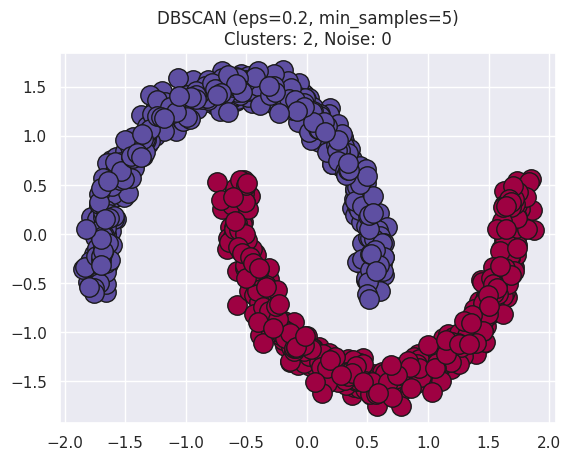

In [83]:
# 4. Visualisasikan hasil DBSCAN
unique_labels = set(labels_db)
core_samples_mask = np.zeros_like(labels_db, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Hitam untuk noise
        col = [0, 0, 0, 1]

    class_member_mask = (labels_db == k)

    # Plot core samples (titik besar)
    xy = X_moons[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    # Plot non-core samples (titik kecil)
    xy = X_moons[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6)

plt.title(f'DBSCAN (eps=0.2, min_samples=5)\nClusters: {n_clusters_db}, Noise: {n_noise_db}')
plt.show()

In [85]:
# 5. Eksperimen Parameter (Mencatat perubahan klaster, noise, dan evaluasi)
print("\n=== Eksperimen Parameter DBSCAN ===")
results = []
eps_list = [0.05, 0.1, 0.3, 0.5]
min_samples_list = [3, 10, 20]

for e in eps_list:
    for m in min_samples_list:
        db_exp = DBSCAN(eps=e, min_samples=m).fit(X_moons)
        lbls = db_exp.labels_

        nc = len(set(lbls)) - (1 if -1 in lbls else 0)
        nn = list(lbls).count(-1)

        if nc > 1: # Hitung V-measure hanya jika berhasil membedakan klaster
            v = metrics.v_measure_score(labels_true, lbls)
        else:
            v = 0

        results.append({
            'eps': e,
            'min_samples': m,
            'clusters': nc,
            'noise': nn,
            'v_measure': round(v, 3)
        })

# Tampilkan hasil eksperimen dalam bentuk tabel
df_results = pd.DataFrame(results)
print(df_results)


=== Eksperimen Parameter DBSCAN ===
     eps  min_samples  clusters  noise  v_measure
0   0.05            3        69    186      0.257
1   0.05           10         3    970      0.049
2   0.05           20         0   1000      0.000
3   0.10            3         2     14      0.943
4   0.10           10         7     57      0.571
5   0.10           20         6    850      0.155
6   0.30            3         2      0      1.000
7   0.30           10         2      0      1.000
8   0.30           20         2      0      1.000
9   0.50            3         2      0      1.000
10  0.50           10         2      0      1.000
11  0.50           20         2      0      1.000
